# **Análise Exploratória de Dados (EDA) do Disque 100**


# **1. Informações sobre o conjunto de dados do Disque 100**

O Disque Direitos Humanos - Disque 100 é um serviço de utilidade pública do Ministério dos Direitos Humanos e da Cidadania, conforme previsto no Decreto nº 10.174, de 13 de dezembro de 2019, destinado a receber demandas relativas a violações de Direitos Humanos, especialmente as que atingem populações em situação de vulnerabilidade social[[1]](https://www.gov.br/pt-br/servicos/denunciar-violacao-de-direitos-humanos)[[2]](https://www.gov.br/mdh/pt-br/acesso-a-informacao/disque-100/disque-100)

### Considerações sobre taxonomia de classificação de denúncias

São objetivos centrais:

- padronizar os dados obtidos pela ONDH em formato acessível ao cidadão;
- subsidiar o fomento e fortalecimento de políticas públicas afetas aos direitos humanos;
- racionalizar e uniformizar o fluxo de encaminhamento de denúncias relativas à violação de direitos humanos;
- facilitar o acesso e manejo das informações; e
- aprimorar o fluxo de informações com os demais órgãos governamentais responsáveis pelo recebimento das denúncias de violação aos direitos humanos, aproximando, na medida do possível, às nomenclaturas e estrutura de tabelas taxonômicas empregadas por cada um desses atores.

### Metodologia de embasamento da taxonomia da ONDH

A metodologia apresenta, em detalhe, cada uma das **Classes, Subclasses, Espécies e Subespécies** que a compõe, discriminadas em uma escala de categorização de quatro níveis:

- Nível 01 – Direitos a serem tutelados sob a perspectiva dos direitos humanos.
- Nível 02 – Bem jurídico em sentido estrito.
- Nível 03 – Espécies de violações a determinado bem jurídico protegido.
- Nível 04 – Detalhamento de violações a determinada espécie.

### Violações de direitos humanos extraídas do manual

- 2.Liberdade (Classe) ..........................................................................................................28
- 2.1. Liberdade Laboral (Subclasse) .....................................................................29
- 2.1.1. Exploração do Trabalho (Espécie) ................................................................29
- 2.1.2. Impedimento de Trabalho/Ofício/Profissão (Espécie) ............................29

---

- 2.2.3. Condição Análoga à de Escravo (Espécie) ..................................................31
- 2.2.3.1. Submeter Trabalhador a Trabalhos Forçados (Subespécie) ...................31
- 2.2.3.2. Sujeitar Trabalhador a Condições Degradantes (Subespécie) ..............33
- 2.2.3.3. Submeter Trabalhador a Jornada Exaustiva (Subespécie) ....................34
- 2.2.3.4. Restringir a Locomoção de Trabalhador em Razão de Dívida (Subespécie) ..............................................................35
- 2.2.3.5. Transportar Trabalhador Para Fins de Exploração (Subespécie)..........36

---

- 2.2.8. Tráfico de Pessoas – Internacional (Espécie) ............................................38
- 2.2.9. Tráfico de Pessoas – Nacional (Espécie) ....................................................39

---

- 2.4.2.2. Exploração Sexual (Subespécie) ................................................................44

### Elementos circunstanciais

**Elementos Circunstanciais** (indicadores de gravidade e de motivação) que poderão ser aplicados, conforme o caso concreto que envolva cada relato denunciado.```

- 2.22. Para fins de adoção
- 2.23. Para fins de atividade ilícita
- 2.24. Para fins de exploração sexual
- 2.25. Para fins de remoção de órgãos/tráfico de órgãos
- 2.26. Para fins de exploração do trabalho

Fonte: [Manual de Taxonomia de Direitos Humanos da ONDH](https://www.gov.br/mdh/pt-br/centrais-de-conteudo/publicacoes/ondh/manual-da-taxonomia-de-direitos-humanos-da-ondh.pdf)


In [1]:
# from google.colab import drive

import warnings
import os

import pandas as pd
import numpy as np

from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# import plotly.graph_objects as go
# import plotly.figure_factory as ff
import plotly.io as pio
# from plotly.subplots import make_subplots

pio.templates.default = 'plotly_white'
warnings.filterwarnings('ignore')
pio.renderers.default

pd.set_option('display.max_rows', 75)

# **2. Carregamento dos dados do Drive e análise de qualidade dos dados**


Dados do Disque 100 armazenados no [Google Drive](https://drive.google.com/drive/u/1/mobile/folders/1pCQF1prfpXeMT7gt4V_1vQ1upu8Ghtcu)


In [14]:
# drive.mount('/content/drive')

In [3]:
# Pasta compartilhada do Google
# disque100 = '/content/drive/MyDrive/dados/Disque 100'

# Pasta local
disque100 = r"C:\Users\deinf.janaelson\Documents\Datasets"

In [4]:
files = []
with os.scandir(disque100) as entries:
    for entry in entries:
        if entry.is_file() and 'csv' in entry.name:
            print(f"{entry.name:<40} {entry.stat().st_size / 1024 ** 2:>10.2f} MB")
            files.append(f"{disque100}/{entry.name}")

files = sorted(files)

FileNotFoundError: [WinError 3] O sistema não pode encontrar o caminho especificado: 'C:\\Users\\deinf.janaelson\\Documents\\Datasets'

In [11]:
def load_csv(filepath, dtype=None, low_memory=True, nrows=None, na_values=None) -> pd.DataFrame:
    try:
        return pd.read_csv(filepath, sep=";", encoding="utf-8", dtype=dtype, low_memory=low_memory, nrows=nrows, na_values=na_values)
    except:
        return pd.read_csv(filepath, sep=";", encoding="latin-1", dtype=dtype, low_memory=low_memory, nrows=nrows, na_values=na_values)

## 2.1 Carregamento de para teste (nome de colunas)

Alguns conjuntos de dados possuem nome de colunas inconsistentes (com inclusão ou não de caracteres especiais entre palavras). Os conjuntos iniciais não possuem "\_" como separador entre palavras que formam variáveis.

- 1: disque100-primeiro-semestre-2021.csv
- 10: disque100-segundo-semestre-2025.csv'


In [12]:
df1 = load_csv(files[0], nrows=0)
df10 = load_csv(files[-1], nrows=0)

## 2.2 Vericação de nomes de colunas


In [13]:
print(f"1º/2021 e 2º/2025 possuem as mesmas colunas: {"Sim" if frozenset(df1.columns) == frozenset(df10.columns) else "Não"}")

1º/2021 e 2º/2025 possuem as mesmas colunas: Não


### Normalização de nomes de colunas com NFKD


In [14]:
import unicodedata
import re

def normalize_text(col):
    col = unicodedata.normalize('NFKD', col).encode('ascii', 'ignore').decode('utf-8')
    # minúsculos
    col = col.lower()
    # substituir espaços e caracteres especiais
    col = re.sub(r'[^\w]+', '_', col)
    # remover underscores duplicados
    col = re.sub(r'_+', '_', col)
    # remover underscore no início/fim
    col = col.strip('_')
    return col

def normalize_columns (columns):
    return [normalize_text(c) for c in columns]

In [15]:
df1.columns = normalize_columns(df1.columns)
df10.columns = normalize_columns(df10.columns)

In [22]:
print(f"1º/2021 e 2º/2025 possuem as mesmas colunas: {"Sim" if frozenset(df1.columns) == frozenset(df10.columns) else "Não"}")

1º/2021 e 2º/2025 possuem as mesmas colunas: Sim


In [23]:
del df1
del df10

In [24]:
dfs = []

for fp in files:
    df = load_csv(fp, nrows=0)
    df.columns = normalize_columns(df.columns)
    dfs.append(df)

In [25]:
equals = len(set(frozenset(df.columns) for df in dfs)) == 1
print(f"As colunas das bases são iguais? {"Sim" if equals else "Não"}")

As colunas das bases são iguais? Não


### Renomeação de colunas

Alguns conjuntos de dados, mesmo após normalização da colunas, divergem nos nomes das colunas ("sexo_da_vitima" e "sexo_da_vitima") e ("genero_da_vitima" e "genero_do_suspeito"), para os anos 2023, 2024 e 2025. Foi observado que as colunas mantém a mesma ordem para os casos de coluna inominada.


In [17]:
def rename_columns(columns):
    rename_map = {
        "sexo_da_vitima": "genero_da_vitima",
        "sexo_do_suspeito": "genero_do_suspeito",
        "nenhum_nome_de_coluna": "grupo_vulneravel"
    }
    return [
        rename_map.get(col.strip().lower(), col)
        for col in columns
    ]

In [27]:
dfs = []

for fp in files:
    df = load_csv(fp, nrows=0)
    df.columns = normalize_columns(df.columns)
    df.columns = rename_columns(df.columns)
    dfs.append(df)

In [28]:
equals = len(set(frozenset(df.columns) for df in dfs)) == 1
print(f"As colunas das bases são iguais? {"Sim" if equals else "Não"}")

columns = [df.columns for df in dfs]
equals = all(np.array_equal(col, columns[0]) for col in columns)
print(f"As colunas das bases são iguais? {"Sim" if equals else "Não"}")

As colunas das bases são iguais? Sim
As colunas das bases são iguais? Sim


In [29]:
del dfs

## 2.3 Carregamento de CSV para teste (tipos, valores únicos e ausentes)


In [ ]:
# Carregamento de conjunto de dados do 2º semestre/2025 como base para nomenclatura de colunas já ajustadas

df10 = load_csv(files[-1], low_memory=False)
df10.columns = normalize_columns(df10.columns)
df10.columns = rename_columns(df10.columns)

In [31]:
df10.head(5)

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,...,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,60065D57B15FDD1A455EFF164E2830112194CBB9FDA3C5...,2025-07-01 00:02:13.137,TELEFÔNICO,NÃO,TERCEIRO,CASA DA VÍTIMA,BR | BRASIL,SP,3548708 | SÃO BERNARDO DO CAMPO,NÃO SABE INFORMAR,...,NaN,NaN,PARDA,NaN,NaN,NaN,NaN,NaN,NaN,INTEGRIDADE>FÍSICA>LESÃO CORPORAL
1,60065D57B15FDD1A455EFF164E2830112194CBB9FDA3C5...,2025-07-01 00:02:13.137,TELEFÔNICO,NÃO,TERCEIRO,CASA DA VÍTIMA,BR | BRASIL,SP,3548708 | SÃO BERNARDO DO CAMPO,NÃO SABE INFORMAR,...,NaN,NaN,PARDA,NaN,NaN,NaN,NaN,NaN,NaN,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,60065D57B15FDD1A455EFF164E2830112194CBB9FDA3C5...,2025-07-01 00:02:13.137,TELEFÔNICO,NÃO,TERCEIRO,CASA DA VÍTIMA,BR | BRASIL,SP,3548708 | SÃO BERNARDO DO CAMPO,NÃO SABE INFORMAR,...,NaN,NaN,PARDA,NaN,NaN,NaN,NaN,NaN,NaN,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
3,60065D57B15FDD1A455EFF164E2830112194CBB9FDA3C5...,2025-07-01 00:02:13.137,TELEFÔNICO,NÃO,TERCEIRO,CASA DA VÍTIMA,BR | BRASIL,SP,3548708 | SÃO BERNARDO DO CAMPO,NÃO SABE INFORMAR,...,NaN,NaN,PARDA,NaN,NaN,NaN,NaN,NaN,NaN,INTEGRIDADE>FÍSICA>EXPOSIÇÃO DE RISCO À SAÚDE
4,C77DCB4D5D8DD59CACB071299B9C524584E2B0717A8146...,2025-07-01 00:02:13.137,TELEFÔNICO,NÃO,TERCEIRO,CASA DA VÍTIMA,BR | BRASIL,SP,3548708 | SÃO BERNARDO DO CAMPO,NÃO SABE INFORMAR,...,NaN,NaN,NÃO INFORMADO,NaN,NaN,NaN,NaN,NaN,NaN,INTEGRIDADE>FÍSICA>EXPOSIÇÃO DE RISCO À SAÚDE


In [32]:
df10.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 2421688 entries, 0 to 2421687
Data columns (total 62 columns):
 #   Column                                          Dtype  
---  ------                                          -----  
 0   hash                                            str    
 1   data_de_cadastro                                str    
 2   canal_de_atendimento                            str    
 3   denuncia_emergencial                            str    
 4   denunciante                                     str    
 5   cenario_da_violacao                             str    
 6   pais                                            str    
 7   uf                                              str    
 8   municipio                                       str    
 9   frequencia                                      str    
 10  inicio_das_violacoes                            str    
 11  sl_quantidade_vitimas                           int64  
 12  grupo_vulneravel                       

In [33]:
df10.describe()

,sl_quantidade_vitimas,sl_vitima_naturalidade,sl_vitima_naturalizado_uf,sl_vitima_naturalizado_municipio,deficiencia_relacionada_a_doenca_rara,sl_suspeito_naturalidade,sl_suspeito_naturalizado_uf,sl_suspeito_naturalizado_municipio,deficiencia_relacionada_a_doenca_rara_suspeito,grau_de_instrucao_do_suspeito,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito
count,2.421688e+06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,1.337811e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,6.451985e-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,7.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Análise de tipos de dados


In [34]:
for col in df10.select_dtypes(include=np.number):
    if not np.isfinite(df10[col]).all():
        print(f"A coluna '{col}' tem todos os valores ausentes (NaN)")

A coluna 'sl_vitima_naturalidade' tem todos os valores ausentes (NaN)
A coluna 'sl_vitima_naturalizado_uf' tem todos os valores ausentes (NaN)
A coluna 'sl_vitima_naturalizado_municipio' tem todos os valores ausentes (NaN)
A coluna 'deficiencia_relacionada_a_doenca_rara' tem todos os valores ausentes (NaN)
A coluna 'sl_suspeito_naturalidade' tem todos os valores ausentes (NaN)
A coluna 'sl_suspeito_naturalizado_uf' tem todos os valores ausentes (NaN)
A coluna 'sl_suspeito_naturalizado_municipio' tem todos os valores ausentes (NaN)
A coluna 'deficiencia_relacionada_a_doenca_rara_suspeito' tem todos os valores ausentes (NaN)
A coluna 'grau_de_instrucao_do_suspeito' tem todos os valores ausentes (NaN)
A coluna 'faixa_de_renda_do_suspeito' tem todos os valores ausentes (NaN)
A coluna 'vinculo_orgao_pj_do_suspeito' tem todos os valores ausentes (NaN)


### Registros únicos por coluna


In [35]:
df10.nunique().sort_values(ascending=False)

hash                                              331251
data_de_cadastro                                  192507
sl_suspeito_municipio                               5051
municipio                                           5048
municipio_da_vitima                                 5046
violacao                                             121
profissao_do_suspeito                                 70
pais_do_suspeito                                      63
relacao_vitima_suspeito                               53
pais                                                  43
pais_da_vitima                                        42
suspeito_nacionalidade                                41
sl_suspeito_ramo                                      39
faixa_etaria_da_vitima                                38
profissao_da_vitima                                   38
nacionalidade_da_vitima                               33
doenca_rara_da_vitima                                 32
cenario_da_violacao            

In [36]:
df10.dtypes

hash                                                  str
data_de_cadastro                                      str
canal_de_atendimento                                  str
denuncia_emergencial                                  str
denunciante                                           str
cenario_da_violacao                                   str
pais                                                  str
uf                                                    str
municipio                                             str
frequencia                                            str
inicio_das_violacoes                                  str
sl_quantidade_vitimas                               int64
grupo_vulneravel                                      str
motivacao                                             str
relacao_vitima_suspeito                               str
sl_vitima_cadastro                                    str
genero_da_vitima                                      str
orientacao_sex

In [37]:
obj_cols = df10.select_dtypes(exclude=np.number).columns.drop(["hash", "data_de_cadastro"])

for col in obj_cols:
    print("-" * 70, "\n")
    print(df10[col].value_counts().sort_values(ascending=False))
    print("\n")

---------------------------------------------------------------------- 

canal_de_atendimento
TELEFÔNICO      2031252
WHATSAPP         345586
E-MAIL            27253
PROCESSO SEI       9531
WEBCHAT            3569
TELEGRAM           2681
PRESENCIAL         1527
CARTA               280
VIDEOCHAMADA          7
APLICATIVO            2
Name: count, dtype: int64


---------------------------------------------------------------------- 

denuncia_emergencial
NÃO                                                            2312629
RISCO IMINENTE DE MORTE DA VÍTIMA                                90771
SITUAÇÃO FLAGRANTE - ATÉ 24H DA OCORRÊNCIA - SEM FREQUÊNCIA      16949
VÍTIMA EM SANGRAMENTO                                             1339
Name: count, dtype: int64


---------------------------------------------------------------------- 

denunciante
TERCEIRO              2007116
A PRÓPRIA VÍTIMA       413682
O PRÓPRIO AGRESSOR        875
Name: count, dtype: int64


-----------------------------

In [19]:
dtypes = {
    "hash": "string",
    "municipio": "string",
    "municipio_da_vitima": "string",
    "sl_suspeito_municipio": "string",
    "sl_quantidade_vitimas": "Int16",
}

datetime_col = ["data_de_cadastro"]

# Converter tipos de datas divergente em bases de dados ora em formato inglês ora em português
def parse_mixed_date(col: pd.Series) -> pd.Series:
    # 1. Tenta formato ISO (ex: 2025-07-01 00:02:13.137)
    dt_iso = pd.to_datetime(
        col,
        errors='coerce',
        format='%Y-%m-%d %H:%M:%S.%f'
    )
    
    # 2. Tenta formato BR com hora (ex: 02/01/2021 10:37)
    dt_br = pd.to_datetime(
        col,
        errors='coerce',
        dayfirst=True
    )
    
    # 3. Combina os resultados
    return dt_iso.fillna(dt_br)


# Colunas restantes
cat_cols = set(df10.columns) - set(dtypes) - set(datetime_col)

dtypes.update({col: "category" for col in cat_cols})


In [39]:
# Conversão de tipos
df10['data_de_cadastro'] = parse_mixed_date(df10['data_de_cadastro'])
df10 = df10.astype(dtypes)

In [40]:
df10.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 2421688 entries, 0 to 2421687
Data columns (total 62 columns):
 #   Column                                          Dtype         
---  ------                                          -----         
 0   hash                                            string        
 1   data_de_cadastro                                datetime64[us]
 2   canal_de_atendimento                            category      
 3   denuncia_emergencial                            category      
 4   denunciante                                     category      
 5   cenario_da_violacao                             category      
 6   pais                                            category      
 7   uf                                              category      
 8   municipio                                       string        
 9   frequencia                                      category      
 10  inicio_das_violacoes                            category      
 11  sl_quanti

### Análise de valores ausentes


In [41]:
print("---Valores ausentes reais---\n")
df10.isna().sum().sort_values(ascending=False)

---Valores ausentes reais---



sl_vitima_naturalizado_uf                         2421688
sl_vitima_naturalidade                            2421688
sl_vitima_naturalizado_municipio                  2421688
deficiencia_relacionada_a_doenca_rara             2421688
sl_suspeito_naturalizado_municipio                2421688
sl_suspeito_naturalizado_uf                       2421688
deficiencia_relacionada_a_doenca_rara_suspeito    2421688
grau_de_instrucao_do_suspeito                     2421688
faixa_de_renda_do_suspeito                        2421688
vinculo_orgao_pj_do_suspeito                      2421688
sl_suspeito_naturalidade                          2421688
vitima_especificacao_etnia                        2419742
suspeito_etnia                                    2418265
suspeito_especificacao_etnia                      2414276
etnia_da_vitima                                   2404468
profissao_da_vitima                               2368310
faixa_de_renda_da_vitima                          2348517
religiao_do_su

#### Análise de valores ausentes com base nos dados do 2º semestre/2025

Análise da qualidade de dados do 'dataset' que contém valores textuais que representam semanticamente a ausência de informação.

Com base no dataset , os principais são:

- Ausência explícita: "NULO", "nulo", "" (string vazia) ou nan (já reconhecido pelo pandas)
- Ausência por desconhecimento: "NÃO INFORMADO", "NAO INFORMADO", "NÃO SABE INFORMAR", "NÃO SABE", "IGNORADO" ou "SEM INFORMACAO"
- Ausência contextual / não aplicável: "NÃO SE APLICA", "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
- Ausência operacional : "ATENDIMENTO INTERROMPIDO"
- Ausência (campo inválido para contexto):"DENUNCIANTE NÃO SOUBE INFORMAR"

Tipos diferentes:

- Estrutural: não existe dado (nulo)
- Informacional: não soube responder
- Semântico: não se aplica
- Operacional: falha no processo


In [42]:
missing_value_placeholders = [
    # básicos
    "NULO", 
    "nulo", 
    "", 
    "null", 
    "NULL", 
    "N/D", 
    "N/A",

    # desconhecido
    "NÃO INFORMADO", "NAO INFORMADO",
    "NÃO SABE INFORMAR", "NÃO SABE",
    "IGNORADO", "SEM INFORMACAO",

    # não aplicável
    "NÃO SE APLICA",
    "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA",
    "IDOSO IDADE NÃO INFORMADA",

    # operacionais
    "ATENDIMENTO INTERROMPIDO",

    # variações específicas
    "DENUNCIANTE NÃO SOUBE INFORMAR"
]

placeholders_norm = {str(x).strip().upper() for x in missing_value_placeholders}

In [43]:
df10["genero_da_vitima"].value_counts()

genero_da_vitima
FEMININO                                     1249014
MASCULINO                                     993142
NÃO INFORMADO                                  28400
NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA       4685
INTERSEXO                                       1132
Name: count, dtype: int64

In [44]:
# placeholders_norm = {str(x).strip().upper() for x in missing_value_placeholders}

def map_semantic_missing_with_counts(df: pd.DataFrame, placeholders_norm) -> dict:
    
    result = {}

    for col in df.columns:
        col_norm = df[col].astype(str).str.strip().str.upper()
        
        mask = col_norm.isin(placeholders_norm)
        
        if mask.any():
            counts = df.loc[mask, col].value_counts(dropna=False).to_dict()
            result[col] = counts

    return result

def filter_semantic_missing(df, col, placeholders_norm) -> pd.DataFrame:

    # Normaliza os valores da coluna
    col_norm = df[col].astype(str).str.strip().str.upper()

    # Retorna as linhas cujo valor está nos placeholders
    return df[col_norm.isin(placeholders_norm)]

def replace_semantic_missing(df: pd.DataFrame) -> pd.DataFrame:
    
    df_clean = df.copy()

    for col in df_clean.columns:
        col_norm = df_clean[col].astype(str).str.strip().str.upper()
        df_clean.loc[col_norm.isin(placeholders_norm), col] = pd.NA

        # 🔥 Remove categorias não utilizadas (se for categórico)
        if pd.api.types.is_categorical_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].cat.remove_unused_categories()

    return df_clean

In [45]:
filter_semantic_missing(df10, "genero_da_vitima", placeholders_norm)["genero_da_vitima"]

208        NÃO INFORMADO
209        NÃO INFORMADO
210        NÃO INFORMADO
211        NÃO INFORMADO
212        NÃO INFORMADO
               ...      
2421454    NÃO INFORMADO
2421455    NÃO INFORMADO
2421456    NÃO INFORMADO
2421457    NÃO INFORMADO
2421458    NÃO INFORMADO
Name: genero_da_vitima, Length: 33085, dtype: category
Categories (5, str): ['FEMININO', 'INTERSEXO', 'MASCULINO', 'NÃO INFORMADO', 'NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA']

In [46]:
df_cleaned = replace_semantic_missing(df10)

In [47]:
df_cleaned["genero_da_vitima"].value_counts()

genero_da_vitima
FEMININO     1249014
MASCULINO     993142
INTERSEXO       1132
Name: count, dtype: int64

In [48]:
df_cleaned["genero_da_vitima"].isnull().sum()

np.int64(178400)

In [49]:
missing_values = df_cleaned.isna().mean() * 100
missing_values = missing_values.sort_values(ascending=False)

In [50]:
fig = px.bar(
    x=missing_values.index,
    y=missing_values.values,
    labels={"x": "Variáveis", "y": "Porcentagem (%)"},
    title="Análise de valores ausentes reais e semânticos"
)

fig.update_layout(
    xaxis_tickangle=60,
    yaxis=dict(range=[0, 100]),
    height=800
)

fig.show()

In [51]:

# Limite de valores ausentes 
threshold = 0.3

# Proporção de valores ausentes por coluna
missing_proportions = df10.isnull().sum() / len(df10)

# Colunas onde a proporção de valores ausentes é maior que o limite
columns_to_drop = missing_proportions[missing_proportions > threshold].index.tolist()

# DataFrame com colunas removidas
df_filtered = df10.drop(columns=columns_to_drop)

print(f"\nColumns dropped due to missing values > {threshold*100}%: \n{columns_to_drop}")
print("DataFrame after dropping columns:", df_filtered.shape)


Columns dropped due to missing values > 30.0%: 
['motivacao', 'sl_vitima_naturalidade', 'sl_vitima_naturalizado_uf', 'sl_vitima_naturalizado_municipio', 'deficiencia_da_vitima', 'deficiencia_relacionada_a_doenca_rara', 'profissao_da_vitima', 'grau_de_instrucao_da_vitima', 'religiao_da_vitima', 'etnia_da_vitima', 'faixa_de_renda_da_vitima', 'sl_suspeito_naturalidade', 'sl_suspeito_naturalizado_uf', 'sl_suspeito_naturalizado_municipio', 'deficiencia_do_suspeito', 'deficiencia_relacionada_a_doenca_rara_suspeito', 'grau_de_instrucao_do_suspeito', 'religiao_do_suspeito', 'raca_cor_do_suspeito', 'suspeito_etnia', 'faixa_de_renda_do_suspeito', 'vinculo_orgao_pj_do_suspeito', 'sl_suspeito_ramo', 'suspeito_especificacao_etnia', 'vitima_especificacao_etnia']
DataFrame after dropping columns: (2421688, 37)


In [ ]:
del df10
del df_cleaned
del missing_values
del missing_proportions
del df_filtered

# **3. EDA do Disque 100**


In [21]:
import unicodedata
import re

def normalize_text(col):
    # remover acentos
    col = unicodedata.normalize('NFKD', col).encode('ascii', 'ignore').decode('utf-8')
    # minúsculos
    col = col.lower()
    # substituir espaços e caracteres especiais
    col = re.sub(r'[^\w]+', '_', col)
    # remover underscores duplicados
    col = re.sub(r'_+', '_', col)
    # remover underscore no início/fim
    col = col.strip('_')
    return col

def normalize_columns (columns):
    return [normalize_text(c) for c in columns]

def rename_columns(columns):
    rename_map = {
        "sexo_da_vitima": "genero_da_vitima",
        "sexo_do_suspeito": "genero_do_suspeito",
        "nenhum_nome_de_coluna": "grupo_vulneravel"
    }
    return [
        rename_map.get(col.strip().lower(), col)
        for col in columns
    ]

# Converter tipos de datas divergente em bases de dados ora em formato inglês ora em português
def parse_mixed_date(col: pd.Series) -> pd.Series:
    # 1. Tenta formato ISO (ex: 2025-07-01 00:02:13.137)
    dt_iso = pd.to_datetime(
        col,
        errors='coerce',
        format='%Y-%m-%d %H:%M:%S.%f'
    )
    
    # 2. Tenta formato BR com hora (ex: 02/01/2021 10:37)
    dt_br = pd.to_datetime(
        col,
        errors='coerce',
        dayfirst=True
    )
    
    # 3. Combina os resultados
    return dt_iso.fillna(dt_br)

def load_csv(filepath, dtype=None, low_memory=True, nrows=None, na_values=None) -> pd.DataFrame:
    try:
        return pd.read_csv(filepath, sep=";", encoding="utf-8", dtype=dtype, low_memory=low_memory, nrows=nrows, na_values=na_values)
    except:
        return pd.read_csv(filepath, sep=";", encoding="latin-1", dtype=dtype, low_memory=low_memory, nrows=nrows, na_values=na_values)

In [54]:
dtypes

{'hash': 'string',
 'municipio': 'string',
 'municipio_da_vitima': 'string',
 'sl_suspeito_municipio': 'string',
 'sl_quantidade_vitimas': 'Int16',
 'deficiencia_do_suspeito': 'category',
 'sl_vitima_naturalizado_municipio': 'category',
 'religiao_do_suspeito': 'category',
 'sl_vitima_naturalidade': 'category',
 'suspeito_etnia': 'category',
 'orientacao_sexual_do_suspeito': 'category',
 'violacao': 'category',
 'genero_da_vitima': 'category',
 'sl_vitima_naturalizado_uf': 'category',
 'deficiencia_relacionada_a_doenca_rara': 'category',
 'etnia_da_vitima': 'category',
 'denuncia_emergencial': 'category',
 'faixa_etaria_do_suspeito': 'category',
 'deficiencia_da_vitima': 'category',
 'pais_da_vitima': 'category',
 'nacionalidade_da_vitima': 'category',
 'sl_suspeito_naturalidade': 'category',
 'vitima_especificacao_etnia': 'category',
 'uf_do_suspeito': 'category',
 'suspeito_preso': 'category',
 'faixa_de_renda_da_vitima': 'category',
 'doenca_rara_do_suspeito': 'category',
 'relacao_

In [55]:
dtypes = {
    "hash": "string",
    "municipio": "string",
    "municipio_da_vitima": "string",
    "sl_suspeito_municipio": "string",
    "sl_quantidade_vitimas": "Int16",
}

datetime_col = ["data_de_cadastro"]

cat_cols = [
    "canal_de_atendimento",
    "denuncia_emergencial",
    "denunciante",
    "cenario_da_violacao",
    "pais",
    "uf",
    "frequencia",
    "inicio_das_violacoes",
    "grupo_vulneravel",
    "motivacao",
    "relacao_vitima_suspeito",
    "sl_vitima_cadastro",
    "genero_da_vitima",
    "orientacao_sexual_da_vitima",
    "faixa_etaria_da_vitima",
    "nacionalidade_da_vitima",
    "sl_vitima_naturalidade",
    "sl_vitima_naturalizado_uf",
    "sl_vitima_naturalizado_municipio",
    "deficiencia_da_vitima",
    "doenca_rara_da_vitima",
    "deficiencia_relacionada_a_doenca_rara",
    "vitima_preso_a",
    "pais_da_vitima",
    "uf_da_vitima",
    "profissao_da_vitima",
    "grau_de_instrucao_da_vitima",
    "religiao_da_vitima",
    "raca_cor_da_vitima",
    "etnia_da_vitima",
    "faixa_de_renda_da_vitima",
    "natureza_juridica_do_suspeito",
    "genero_do_suspeito",
    "orientacao_sexual_do_suspeito",
    "faixa_etaria_do_suspeito",
    "suspeito_nacionalidade",
    "sl_suspeito_naturalidade",
    "sl_suspeito_naturalizado_uf",
    "sl_suspeito_naturalizado_municipio",
    "deficiencia_do_suspeito",
    "doenca_rara_do_suspeito",
    "deficiencia_relacionada_a_doenca_rara_suspeito",
    "suspeito_preso",
    "pais_do_suspeito",
    "uf_do_suspeito",
    "profissao_do_suspeito",
    "grau_de_instrucao_do_suspeito",
    "religiao_do_suspeito",
    "raca_cor_do_suspeito",
    "suspeito_etnia",
    "faixa_de_renda_do_suspeito",
    "vinculo_orgao_pj_do_suspeito",
    "sl_suspeito_ramo",
    "suspeito_especificacao_etnia",
    "vitima_especificacao_etnia",
    "violacao"
]

dtypes.update({col: "category" for col in cat_cols})

missing_value_placeholders = [
    # básicos
    "NULO", 
    "nulo", 
    "", 
    "null", 
    "NULL", 
    "N/D", 
    "N/A",

    # desconhecido
    "NÃO INFORMADO", "NAO INFORMADO",
    "NÃO SABE INFORMAR", "NÃO SABE",
    "IGNORADO", "SEM INFORMACAO",

    # não aplicável
    "NÃO SE APLICA",
    "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA",
    "CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA",
    "IDOSO IDADE NÃO INFORMADA",

    # operacionais
    "ATENDIMENTO INTERROMPIDO",

    # variações específicas
    "DENUNCIANTE NÃO SOUBE INFORMAR"
]

placeholders_norm = {str(x).strip().upper() for x in missing_value_placeholders}

## 3.1 Carregamento de todos os datasets (2021 a 2025)


In [56]:
dfs = []
for file in files:
  df = load_csv(os.path.join(disque100, file), low_memory=False)
  print(f"'{file}' carregado.")
  df.columns = normalize_columns(df.columns)
  df.columns = rename_columns(df.columns)  
  dfs.append(df)
  del df

'C:\Users\deinf.janaelson\Documents\Datasets/disque100-primeiro-semestre-2021.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-primeiro-semestre-2022.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-primeiro-semestre-2023.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-primeiro-semestre-2024.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-primeiro-semestre-2025.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-segundo-semestre-2021.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-segundo-semestre-2022.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-segundo-semestre-2023.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-segundo-semestre-2024.csv' carregado.
'C:\Users\deinf.janaelson\Documents\Datasets/disque100-segundo-semestre-2025.csv' carregado.


In [57]:
df = pd.concat(dfs, ignore_index=True)
del dfs

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13796830 entries, 0 to 13796829
Data columns (total 62 columns):
 #   Column                                          Dtype 
---  ------                                          ----- 
 0   hash                                            str   
 1   data_de_cadastro                                str   
 2   canal_de_atendimento                            str   
 3   denuncia_emergencial                            str   
 4   denunciante                                     str   
 5   cenario_da_violacao                             str   
 6   pais                                            str   
 7   uf                                              str   
 8   municipio                                       str   
 9   frequencia                                      str   
 10  inicio_das_violacoes                            str   
 11  sl_quantidade_vitimas                           int64 
 12  grupo_vulneravel                                str

### Conversão dos tipos das colunas mapeadas


In [64]:
# cat_cols = set(df.columns) - set(dtypes) - set(datetime_col)
# dtypes.update({col: "category" for col in cat_cols})
df['data_de_cadastro'] = parse_mixed_date(df['data_de_cadastro'])
df = df.astype(dtypes)

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13796830 entries, 0 to 13796829
Data columns (total 62 columns):
 #   Column                                          Dtype         
---  ------                                          -----         
 0   hash                                            string        
 1   data_de_cadastro                                datetime64[us]
 2   canal_de_atendimento                            category      
 3   denuncia_emergencial                            category      
 4   denunciante                                     category      
 5   cenario_da_violacao                             category      
 6   pais                                            category      
 7   uf                                              category      
 8   municipio                                       string        
 9   frequencia                                      category      
 10  inicio_das_violacoes                            category      
 11  sl_quan

In [70]:
df.describe()

,data_de_cadastro,sl_quantidade_vitimas
count,13796830,13796830.0
mean,2024-03-12 19:08:19.272216,3.166887
min,2021-01-01 00:01:00,1.0
25%,2023-04-22 08:39:36.747000,1.0
50%,2024-05-28 16:41:57.968500,1.0
75%,2025-04-04 09:51:18.973000,2.0
max,2025-12-31 23:57:15.683000,60.0
std,NaN,6.345623


### Armazenamento dos arquivo .CSV juntados com tipos (otimizado) para posterior utilização


In [23]:
output_folder = os.path.join(disque100, "Juntado")
os.makedirs(output_folder, exist_ok=True)

output_filepath = os.path.join(output_folder, "disque100-2021-2025.csv")

In [ ]:
# df.to_csv(output_filepath, index=False, sep=";", encoding="utf-8")
# print(f"DataFrame saved to: {output_filepath}")

DataFrame saved to: C:\Users\deinf.janaelson\Documents\Datasets\Juntado\disque100-2021-2025.csv


In [ ]:
# df = load_csv(output_filepath, low_memory=False, dtype=dtypes)
# df["data_de_cadastro"] = parse_mixed_date(df["data_de_cadastro"])

In [25]:
# df.info()

### Criação de variáveis

1. Separar por "|":

Informação geral

- pais

Vítima

- nacionalidade_da_vitima
- pais_da_vitima

Suspeito

- suspeito_nacionalidade
- pais_do_suspeito

Município

- municipio
- municipio_da_vitima
- sl_suspeito_municipio

2. Separar por ">"

- Violação


## 3.2 Análise de valores duplicados


In [ ]:
# Filtra somente linhas que são duplicadas, ignorando a coluna 'violacao'.
duplicates_v = df[df.duplicated(subset=df.columns.difference(['violacao']), keep='first')]
print("# Quantidade de valores duplicados desconsiderando a coluna 'violacao'\n")
print(f"Valores duplicados: {duplicates_v.shape[0]}")
print(f"Valores não duplicados: {df.shape[0] - duplicates_v.shape[0]}")

# Quantidade de valores duplicados desconsiderando a coluna 'violacao'

Valores duplicados: 6683394
Valores não duplicados: 7113436


In [80]:
# Filtra somente linhas que são duplicadas, ignorando a coluna 'hash'.
duplicates_h = df[df.duplicated(subset=df.columns.difference(['hash']), keep='first')]
print("# Quantidade de valores duplicados desconsiderando a coluna 'hash'\n")
print(f"Valores duplicados: {duplicates_h.shape[0]}")
print(f"Valores não duplicados: {df.shape[0] - duplicates_h.shape[0]}")


# Quantidade de valores duplicados desconsiderando a coluna 'hash'

Valores duplicados: 378087
Valores não duplicados: 13418743


In [81]:
# Filtra somente linhas que são duplicadas, ignorando a coluna 'hash' e 'data_de_cadastro'.
duplicates_hc = df[df.duplicated(subset=df.columns.difference(['hash', 'data_de_cadastro']), keep='first')]
print("# Quantidade de valores duplicados desconsiderando as colunas 'hash' e 'data_de_cadastro'\n")
print(f"Valores duplicados: {duplicates_hc.shape[0]}")
print(f"Valores não duplicados: {df.shape[0] - duplicates_hc.shape[0]}")


# Quantidade de valores duplicados desconsiderando as colunas 'hash' e 'data_de_cadastro'

Valores duplicados: 506059
Valores não duplicados: 13290771


In [82]:
# Filtra somente linhas que são duplicadas considerando a coluna 'hash' e 'violacao'.
duplicates_hv = df[df.duplicated(subset=df.columns.difference(['hash', 'violacao']), keep='first')]
print("# Quantidade de valores duplicados desconsiderando as colunas 'hash' e violação\n")
print(f"Valores duplicados: {duplicates_hv.shape[0]}")
print(f"Valores não duplicados: {df.shape[0] - duplicates_hv.shape[0]}") 

# Quantidade de valores duplicados desconsiderando as colunas 'hash' e violação

Valores duplicados: 6866807
Valores não duplicados: 6930023


In [83]:
# Filtra somente linhas que são duplicadas com as colunas 'hash' e 'violacao'.
duplicates_hv_ = df[df.duplicated(subset=(['hash', 'violacao']), keep='first')]
print("# Quantidade de valores duplicados considerando as colunas 'hash' e violação\n")
print(f"Valores duplicados: {duplicates_hv_.shape[0]}")
print(f"Valores não duplicados: {df.shape[0] - duplicates_hv_.shape[0]}")

# Quantidade de valores duplicados considerando as colunas 'hash' e violação

Valores duplicados: 2309108
Valores não duplicados: 11487722


In [90]:
print("# Quantidade de violações registradas no subconjunto de valores duplicados (ignorando a coluna 'hash')\n")
duplicates_h.groupby(['violacao']).size().reset_index(name='count').sort_values('count', ascending=False).head(20)

# Quantidade de violações registradas no subconjunto de valores duplicados (ignorando a coluna 'hash')



,violacao,count
49,INTEGRIDADE>NEGLIGÊNCIA,50989
40,INTEGRIDADE>FÍSICA>EXPOSIÇÃO DE RISCO À SAÚDE,40884
64,INTEGRIDADE>PSÍQUICA>TORTURA PSÍQUICA,39717
44,INTEGRIDADE>FÍSICA>MAUS TRATOS,29585
63,INTEGRIDADE>PSÍQUICA>INSUBSISTÊNCIA AFETIVA,23882
58,INTEGRIDADE>PSÍQUICA>CONSTRANGIMENTO,23164
60,INTEGRIDADE>PSÍQUICA>EXPOSIÇÃO,20340
38,INTEGRIDADE>FÍSICA>ABANDONO,16773
54,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO,16127
39,INTEGRIDADE>FÍSICA>AGRESSÃO ou VIAS DE FATO,12355


In [ ]:
print("Quantidade de duplicidade de violações por hash\n")

violacao_hash = (
    df.groupby('hash')['violacao']
    .nunique()
    .reset_index(name='qtd_violacoes')
)

only_multiples = violacao_hash[violacao_hash['qtd_violacoes'] > 1]

only_multiples.sort_values(by="qtd_violacoes", ascending=False).head(20)

Quantidade de duplicidade de violações por hash



,hash,qtd_violacoes
1864759,EB58DEFC129CA6AC9682910233ACE6B2C3F26133C0F223...,48
1742035,D9A116AB214FAB1EE16A061543E7DE0AD921558A5D4CE0...,48
408986,3099F7553691B8E7A34DFBF74D483EB2945145C62D4E4D...,48
878312,6894f7f6df6f5c30c8b1a7236d473f46,38
175424,14FA196943254DCEE7558A46FD01F7C03D585E490D6F88...,35
1921903,F39589D864EE75CC234AACB1B9B87A03349137241ED1ED...,35
1045239,7D0E1AB7CD9E5CBD0FD5DA3583CB2E626615F7778CA845...,32
1453516,B01B142A8A66EF1A43A71F3C59BB7462C1DA59B2D8C614...,32
712266,54D9020C667C70FC63E792D58FA5041B49664200C0B27B...,32
637781,4C52CE707FA723EDF2839E8BA47AEF81E5621550B0E844...,31


In [94]:
# del duplicates_v
# del duplicates_h
# del duplicates_hc
# del duplicates_hv
# del duplicates_hv_
# del violacao_hash
# del only_multiples

### Análise de valores ausentes/faltantes


In [95]:
missing_values = df.isnull().mean().multiply(100).sort_values(ascending=False)

In [96]:
fig_missing = px.bar(x=missing_values.index, y=missing_values.values, title="Percentual de valores ausentes reais (NA)", labels={'x':'Variável', 'y':'Porcentagem %'}, color=missing_values.index)
fig_missing.update_layout(yaxis_range=[0, 100], height=700)
fig_missing.show()

In [97]:
normalize = False
results = []

for col in df.columns:
    series = df[col].astype(str).str.strip().str.upper()
    mask = series.isin([v.upper() for v in placeholders_norm])
    count = mask.sum()
    total = len(df)
    value = count / total if normalize else count
    if count > 0:
        results.append({
            "coluna": col,
            "missing_semantico": value
        })

result_df = pd.DataFrame(results).sort_values(by="missing_semantico", ascending=False)

In [98]:
fig = px.bar(
    result_df,
    x="coluna",
    y="missing_semantico",
    title="Valores Ausentes Semânticos por Coluna",
    color="coluna"
    # text="missing_semantico"
)

fig.update_layout(
    xaxis_title="Coluna",
    yaxis_title="Proporção" if normalize else "Quantidade",
    height=700
)

fig.show()

In [ ]:
# del missing_values
# del result_df

### Distribuição por "gênero da vítima"


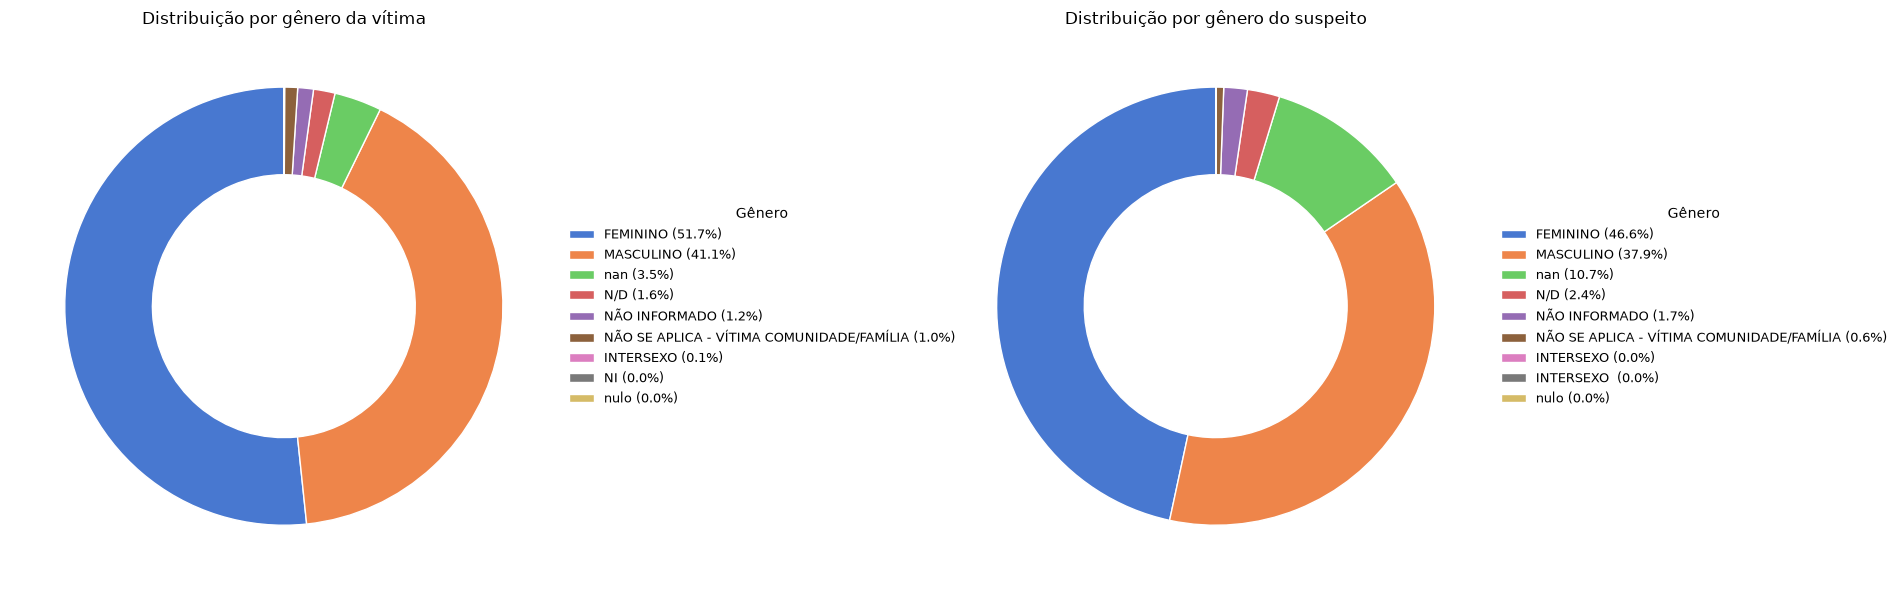

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for ax, col, titulo in zip(
    axes,
    ["genero_da_vitima", "genero_do_suspeito"],
    ["Distribuição por gênero da vítima",
     "Distribuição por gênero do suspeito"]
):

    contagem = df[col].value_counts(dropna=False)

    pct = contagem / contagem.sum() * 100

    cores = sns.color_palette("muted", len(contagem))

    wedges, _ = ax.pie(
        contagem.values,
        startangle=90,
        colors=cores,
        wedgeprops=dict(width=0.4, edgecolor="white")
    )

    total = contagem.sum()

    labels = [
        f"{cat} ({100 * valor / total:.1f}%)"
        for cat, valor in zip(contagem.index, contagem.values)
    ]

    ax.legend(
        wedges,
        labels,
        title="Gênero",
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        frameon=False,
        fontsize=9
    )

    ax.set_title(titulo)

plt.tight_layout()
plt.show()

In [ ]:
# def replace_missing_values(df_plot, col):

#     df = df_plot.copy()

#     if "NÃO INFORMADO" not in df[col].cat.categories:
#         df[col] = df[col].cat.add_categories(["NÃO INFORMADO"])

#     df[col] = (
#         df[col]
#         .replace({
#             "N/D": "NÃO INFORMADO",
#             "NI": "NÃO INFORMADO",
#             "nulo": "NÃO INFORMADO",
#             "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA": "NÃO INFORMADO"
#         })
#         .fillna("NÃO INFORMADO")
#         .cat.remove_unused_categories()
#     )

#     return df[col]   # <- Series

#### Quantidade de vítimas por gênero da vítima e suspeito (valores ausentes reais e semânticos tratados)


In [ ]:
df_plot = df.copy()

for col in ["genero_da_vitima", "genero_do_suspeito"]:

    df_plot[col] = (
        df_plot[col]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace({
            "N/D": "NÃO INFORMADO",
            "NI": "NÃO INFORMADO",
            "NULO": "NÃO INFORMADO",
            "NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA": "NÃO INFORMADO"
        })
        .fillna("NÃO INFORMADO")
        .astype("category")
    )

tmp_vitima = (
    df_plot
    .groupby(
        ["sl_quantidade_vitimas", "genero_da_vitima"],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

tmp_suspeito = (
    df_plot
    .groupby(
        ["sl_quantidade_vitimas", "genero_do_suspeito"],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

In [177]:
print(df_temp["genero_da_vitima"].value_counts(dropna=False))
print(df_temp["genero_da_vitima"].cat.categories)

genero_da_vitima
FEMININO         7127569
MASCULINO        5668670
NÃO INFORMADO     992768
INTERSEXO           7823
Name: count, dtype: int64
Index(['FEMININO', 'INTERSEXO', 'MASCULINO', 'NÃO INFORMADO'], dtype='str')


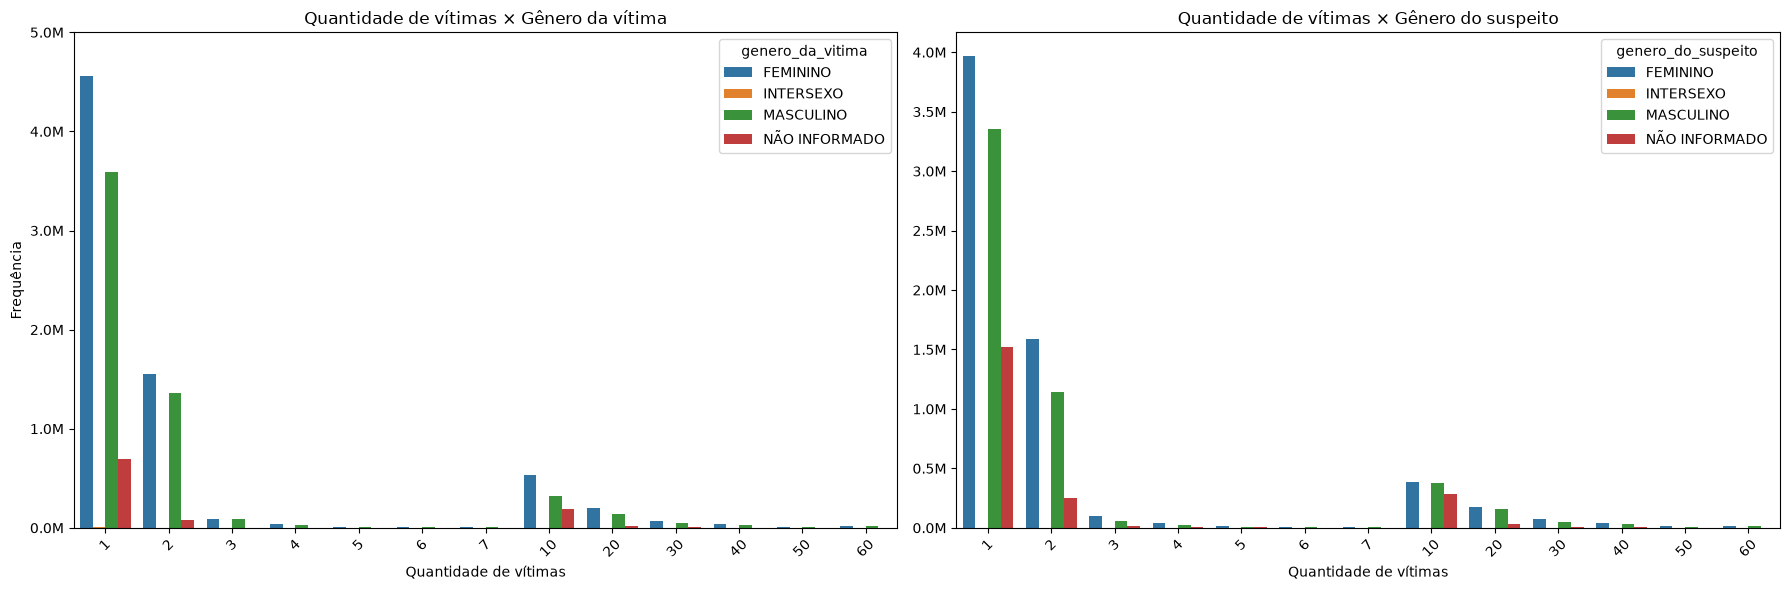

In [167]:
from matplotlib.ticker import FuncFormatter

formatter = FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 6)
)

sns.barplot(
    data=tmp_vitima,
    x="sl_quantidade_vitimas",
    y="frequencia",
    hue="genero_da_vitima",
    ax=axes[0]
)

axes[0].set_title("Quantidade de vítimas × Gênero da vítima")
axes[0].set_xlabel("Quantidade de vítimas")
axes[0].set_ylabel("Frequência")
axes[0].set_ylim(0, 5_000_000)

sns.barplot(
    data=tmp_suspeito,
    x="sl_quantidade_vitimas",
    y="frequencia",
    hue="genero_do_suspeito",
    ax=axes[1]
)

axes[1].set_title("Quantidade de vítimas × Gênero do suspeito")
axes[1].set_xlabel("Quantidade de vítimas")
axes[1].set_ylabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)    
    ax.yaxis.set_major_formatter(formatter)


plt.tight_layout()
plt.show()


In [196]:
import plotly.express as px
import plotly.io as pio

def plot_top_categories(df, col, top_n=10):
    # Contagem
    counts = df[col].value_counts().nlargest(top_n)
    total = counts.sum()

    # DataFrame para plot
    plot_df = counts.reset_index()
    plot_df.columns = [col, "count"]

    # Percentual
    plot_df["pct"] = (plot_df["count"] / total * 100)

    # Ordenação (do menor pro maior para gráfico horizontal bonito)
    plot_df = plot_df.sort_values("count", ascending=True)

    # Rótulo formatado
    plot_df["label"] = plot_df["count"].astype(str) + \
                       " (" + plot_df["pct"].round(1).astype(str) + "%)"

    # Gráfico
    fig = px.bar(
        plot_df,
        x="count",
        y=col,
        orientation="h",
        text="label",
        color="count",
        color_continuous_scale="viridis",
        title=f"Top {top_n} - {col}"
    )

    # Ajustes visuais profissionais
    fig.update_traces(
        textposition="outside"
    )

    fig.update_layout(
        template="plotly_white",
        title_x=0.5,
        xaxis_title="Quantidade",
        yaxis_title="",
        coloraxis_showscale=False,
        margin=dict(l=40, r=40, t=60, b=40),
        height=200 + top_n * 20
    )

    fig.show()

In [197]:
plot_top_categories(df, "faixa_etaria_da_vitima")

In [ ]:
distinct_values = df.nunique().sort_values(ascending=False)
distinct_values_percentage = (distinct_values / len(df)) * 100

fig = px.bar(
    x=distinct_values_percentage.index,
    y=distinct_values_percentage.values,
    title="Valores únicos por Coluna",
    color=distinct_values_percentage.index,
    # text="missing_semantico"
)

fig.update_layout(
    xaxis_title="Coluna",
    yaxis_title="Porcentagem de Valores Únicos (%)",
    height=700
)

fig.show()

In [206]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_heatmap_uf_violacao(df, top_n_violacoes=20):
    grouped = (
        df.groupby(['uf', 'violacao'])
        .size()
        .reset_index(name='quantidade')
    )

    top_violacoes = (
        grouped.groupby('violacao')['quantidade']
        .sum()
        .sort_values(ascending=False)
        .head(top_n_violacoes)
        .index
    )

    filtered = grouped[grouped['violacao'].isin(top_violacoes)]

    pivot = filtered.pivot(index='uf', columns='violacao', values='quantidade').fillna(0)

    plt.figure(figsize=(15, 10))
    sns.heatmap(pivot, cmap='viridis')

    plt.title(f'Mapa de calor UF vs Violação (Top {top_n_violacoes})')
    plt.xlabel('Violação')
    plt.ylabel('UF')

    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

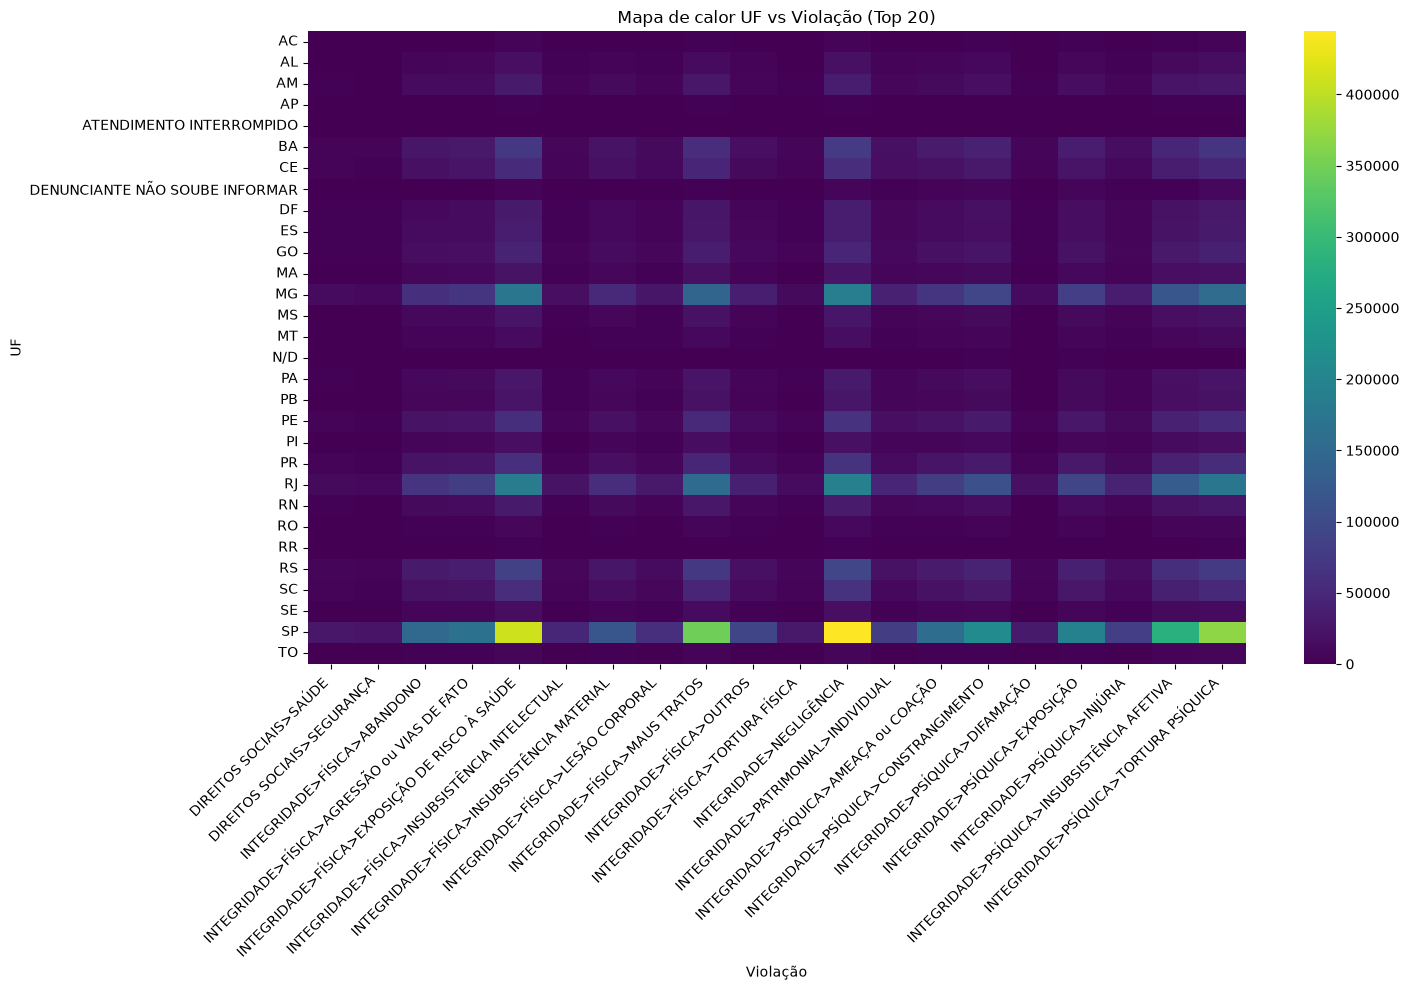

In [207]:
plot_heatmap_uf_violacao(df, top_n_violacoes=20)

### Vítimas por ano


In [210]:
df["ano"] = df["data_de_cadastro"].dt.year
ano_violacao = (
    df.groupby("ano")['violacao']
    .count()
    .reset_index()
    .sort_values("ano")
)

# sns.barplot(result, x='ano', y='violacao')
# plt.show()
fig = px.bar(ano_violacao, x='ano', y='violacao', title="Distribuição de violações por ano")
fig.show()

In [211]:
df["ano"] = df["data_de_cadastro"].dt.year
ano_qtd_vitima = (
    df.groupby("ano")["sl_quantidade_vitimas"]
    .sum()
    .reset_index()
    .sort_values("ano")
)

fig = px.bar(ano_qtd_vitima, x='ano', y='sl_quantidade_vitimas', title="Distribuição de quantidade de vítimas por ano")
fig.show()

### Distribuição por grupo vulnerável - Top 10


In [213]:
plot_top_categories(df, "grupo_vulneravel")

### Distribuição por motivação (elementos circunstanciais) - Top 20


In [214]:
plot_top_categories(df, 'motivacao', top_n=20)

### Distribuição por UF - Top 10


In [215]:
plot_top_categories(df, 'uf')

In [218]:
def plot_top_violacoes_por_uf(df, uf, top_n=10):
    import plotly.express as px

    filtered = df[df['uf'] == uf]

    grouped = (
        filtered['violacao']
        .value_counts()
        .head(top_n)
        .reset_index()
    )

    grouped.columns = ['violacao', 'quantidade']

    fig = px.bar(
        grouped,
        x='violacao',
        y='quantidade',
        title=f'Top {top_n} Violações - {uf}',
        color='violacao',
        color_continuous_scale='Viridis'
    )

    fig.update_layout(xaxis_tickangle=45, xaxis_title="Violação de DH", yaxis_title="Quantidade", height=800)
    fig.show()

In [220]:
plot_top_violacoes_por_uf(df, 'SP', top_n=20)

In [238]:
del df['violacao_grouped'] 

In [239]:
top_n = 10

df_filtered = df.copy()

top_violacoes = df_filtered['violacao'].value_counts().nlargest(top_n).index.tolist()

df_filtered['violacao_grouped'] = df_filtered['violacao'].apply(lambda x: x if x in top_violacoes else 'OUTRAS VIOLAÇÕES')

violacao_por_ano = df_filtered.groupby(['ano', 'violacao_grouped']).size().reset_index(name='contagem')

fig = px.bar(
    violacao_por_ano,
    x='ano',
    y='contagem',
    color='violacao_grouped',
    title=f'Distribuição das Top {top_n} Violações por Ano',
    labels={'ano': 'Ano', 'contagem': 'Contagem de Violações', 'violacao_grouped': 'Tipo de Violação'}
)

fig.update_layout(
    barmode='stack',
    xaxis_title='Ano',
    yaxis_title='Número de Violações',
    legend_title='Tipo de Violação',
    height=700,
    hovermode='x unified' # hover interaction
)

fig.show()


In [ ]:
import pandas as pd
import numpy as np

# Split tratando NaN
df['niveis'] = df['violacao'].apply(
    lambda x: str(x).split(">") if pd.notna(x) else []
)

# Limpar espaços
df['niveis'] = df['niveis'].apply(lambda x: [i.strip() for i in x if i.strip()])

max_niveis = df['niveis'].str.len().max()

niveis_expandidos = pd.DataFrame(
    df['niveis'].tolist(),
    columns=[f'nivel_{i+1}' for i in range(max_niveis)]
)

df = pd.concat([df, niveis_expandidos], axis=1)

df = df.drop(columns='niveis')

In [240]:
def expand_hierarchical_column(df, column, prefix, separator=">"):
    valores = df[column].apply(
        lambda x: str(x).split(separator) if pd.notna(x) else []
    )

    valores = valores.apply(
        lambda x: [item.strip() for item in x if item.strip()]
    )

    max_niveis = valores.str.len().max()

    niveis_expandidos = pd.DataFrame(
        valores.tolist(),
        columns=[f"{column}_{prefix}_{i + 1}" for i in range(max_niveis)]
    )

    return pd.concat(
        [df, niveis_expandidos],
        axis=1
    )

In [ ]:
df = expand_hierarchical_column(df, 'violacao', 'nivel', separator='>')

In [ ]:
Principais tipos de violação

### Principais tipos de violação conforme classificação de taxonomia


In [ ]:
taxonomy = re.findall(r'violacao_nivel_\d+', df.columns.str.cat(sep=' '))

for col in taxonomy:
    print(f'\n---- {col} ----\n')
    print(df[col].value_counts(dropna=False))


---- violacao_nivel_1 ----

violacao_nivel_1
INTEGRIDADE                   12372434
LIBERDADE                       596984
DIREITOS SOCIAIS                492539
nulo                            142706
IGUALDADE                        68336
VIOLÊNCIA INSTITUCIONAL          57818
DIREITOS CIVIS E POLÍTICOS       42334
VIDA                             12492
SEGURANÇA                         6222
MEIO AMBIENTE                     4965
Name: count, dtype: int64

---- violacao_nivel_2 ----

violacao_nivel_2
FÍSICA                                                                 5229620
PSÍQUICA                                                               5167629
NEGLIGÊNCIA                                                            1622016
PATRIMONIAL                                                             358394
SEXUAL                                                                  355053
DIREITOS INDIVIDUAIS                                                    208487
nulo              

In [272]:
uf_violacao = (
    df.groupby(
        ["uf", violacao_final],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

uf_violacao["percentual"] = (
    uf_violacao["frequencia"]
    / uf_violacao.groupby("uf")["frequencia"].transform("sum")
    * 100
)

(
    df["uf"]
    .value_counts()
    .head(10)
)

uf
SP    3699563
RJ    1724224
MG    1566337
RS     766682
BA     680260
PR     533921
PE     533887
SC     501209
CE     491938
GO     394343
Name: count, dtype: int64

In [270]:
regiao_violacao = (
    df.groupby(
        ["regiao", violacao_final],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

regiao_violacao["percentual"] = (
    regiao_violacao["frequencia"]
    / regiao_violacao.groupby("regiao")["frequencia"].transform("sum")
    * 100
)

regiao_violacao.sort_values(
    ["regiao", "percentual"],
    ascending=[True, False]
)

KeyError: 'regiao'

In [267]:
# Retornar o DataFrame com as colunas de código e descrição separadas, mantendo a coluna original intacta e as demais colunas inalteradas. 
# Se não houver separador, a coluna de código terá o valor original e a coluna de descrição será NaN.

def split_code_and_description(
    df,
    source_column,
    code_column,
    description_column,
    separator="|"
):
    parts = (
        df[source_column]
        .astype("string")
        .str.split(separator, n=1, expand=True)
    )

    if parts.shape[1] == 1:
        parts[1] = pd.NA

    df[code_column] = (
        parts[0]
        .str.strip()
        .where(parts[1].notna(), pd.NA)
    )

    df[description_column] = (
        parts[1]
        .str.strip()
        .fillna(parts[0].str.strip())
    )

    return df


### Distribuição por Cidade


In [273]:
df = split_code_and_description(df, "municipio", "codigo_municipio", "nome_municipio")

In [274]:
top_cidades = (
    df["municipio_nome"]
    .value_counts()
    .head(20)
    .index
)

cidade_violacao = (
    df[df["municipio_nome"].isin(top_cidades)]
    .groupby(
        ["municipio_nome", violacao_final],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

In [279]:
top_cidades.sort_values(ascending=False)

Index(['SÃO PAULO', 'SÃO GONÇALO', 'SALVADOR', 'RIO DE JANEIRO', 'RECIFE',
       'PORTO ALEGRE', 'NOVA IGUAÇU', 'NATAL', 'MANAUS', 'GUARULHOS',
       'GOIÂNIA', 'FORTALEZA', 'DUQUE DE CAXIAS',
       'DENUNCIANTE NÃO SOUBE INFORMAR', 'CURITIBA', 'CAMPO GRANDE',
       'CAMPINAS', 'BRASÍLIA', 'BELÉM', 'BELO HORIZONTE'],
      dtype='string', name='municipio_nome')

In [280]:
cidade_violacao.sort_values("frequencia", ascending=False)

,municipio_nome,violacao_nivel_6,frequencia
28,SÃO PAULO,nulo,10661
22,RIO DE JANEIRO,nulo,7769
2,BELO HORIZONTE,nulo,3627
4,BRASÍLIA,nulo,2870
12,FORTALEZA,nulo,2654
15,MANAUS,nulo,2324
23,SALVADOR,nulo,2195
20,RECIFE,nulo,1412
11,DUQUE DE CAXIAS,nulo,1321
5,CAMPINAS,nulo,1288


### Perfil da vítima


In [281]:
perfil_vitima = (
    df.groupby(
        ["genero_da_vitima", violacao_final],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)

perfil_vitima["percentual"] = (
    perfil_vitima["frequencia"]
    / perfil_vitima.groupby("genero_da_vitima")["frequencia"].transform("sum")
    * 100
)

In [282]:
perfil_vitima

,genero_da_vitima,violacao_nivel_6,frequencia,percentual
0,FEMININO,ALIMENTAÇÃO,2,0.002687
1,FEMININO,"AMEAÇA ou COAÇÃO,INTEGRIDADE",1,0.001343
2,FEMININO,DIREITOS INDIVIDUAIS,1,0.001343
3,FEMININO,"EXPOSIÇÃO DE RISCO À SAÚDE,INTEGRIDADE",6,0.008060
4,FEMININO,FÍSICA,4,0.005373
5,FEMININO,"INSUBSISTÊNCIA AFETIVA,INTEGRIDADE",1,0.001343
6,FEMININO,"LESÃO CORPORAL,INTEGRIDADE",1,0.001343
7,FEMININO,"NEGLIGÊNCIA,INTEGRIDADE",1,0.001343
8,FEMININO,PROTEÇÃO À INFÂNCIA,3,0.004030
9,FEMININO,PSÍQUICA,9,0.012089


### Faixa etária da vítima × violação


In [283]:
pd.crosstab(
    df["faixa_etaria_vitima"],
    df[violacao_final],
    normalize="index"
) * 100

KeyError: 'faixa_etaria_vitima'

In [ ]:
relacao_violacao = (
    df.groupby(
        ["vinculo_do_suspeito", violacao_final],
        observed=True
    )
    .size()
    .reset_index(name="frequencia")
)